# Verifica formale e robustezza di reti neurali su GTSRB

Giovanni Norbedo — *Introduction to Machine Learning (UniTS)*

Confronto tra un modello standard (ERM) e uno difeso con adversarial training (PGD) su 5 classi di segnali stradali, usando sia attacchi empirici che verifica esatta con Marabou SMT.

In [40]:
# Flag di configurazione per la riproducibilità
RETRAIN_STANDARD = False    # True: riaddestra il Modello Standard (30 epoche)
RETRAIN_ROBUST = False      # True: riaddestra il Modello Robusto (Mixed AT, 30 epoche)
RETRAIN_PGD_CURVES = False  # True: ricalcola le curve empiriche PGD (1.250 immagini)
RETRAIN_MARABOU = False     # True: riesegue la verifica formale Marabou SMT (250 campioni)

import os
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

warnings.filterwarnings("ignore")

SEED = 67
import random
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


cpu


## Dataset GTSRB

Uso 5 classi: STOP, Precedenza, Limite 30, Limite 50, Divieto.  

Immagini ritagliate sulla ROI annotata, convertite a 28x28 in scala di grigi e normalizzate in [0, 1].  

Split fatto a tracce video disgiunte per evitare data leakage tra frame consecutivi.

Train: 3000, Val: 500, Test: 1250


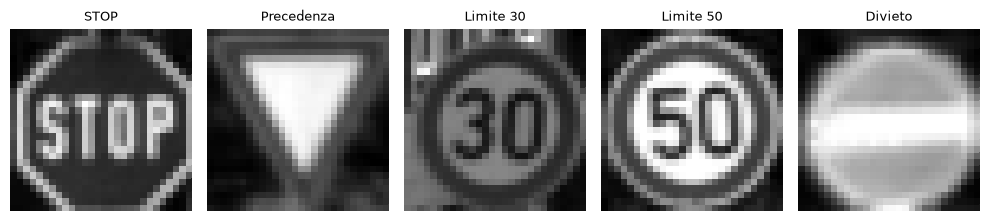

In [41]:
data = torch.load("data/dataset_gtsrb_5class.pt", weights_only=False)
CLASS_NAMES = ["STOP", "Precedenza", "Limite 30", "Limite 50", "Divieto"]

train_loader = DataLoader(data["train_dataset"], batch_size=32, shuffle=True)
val_loader = DataLoader(data["val_dataset"], batch_size=64, shuffle=False)
test_loader = DataLoader(data["test_dataset"], batch_size=64, shuffle=False)

print(f"Train: {len(data['train_dataset'])}, Val: {len(data['val_dataset'])}, Test: {len(data['test_dataset'])}")

# Esempio di un cartello per classe
fig, axes = plt.subplots(1, 5, figsize=(10, 2.2))
for c in range(5):
    idx = (data["y_test"] == c).nonzero()[0].item()
    img = data["X_test"][idx].squeeze().numpy()
    axes[c].imshow(img, cmap="gray")
    axes[c].set_title(CLASS_NAMES[c], fontsize=9)
    axes[c].axis("off")
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/cartelli.png", dpi=150, bbox_inches="tight")
plt.show()

## Architettura: `TrafficSignNet`

MLP a 3 strati con ReLU (2 strati nascosti): 784 -> 64 -> 32 -> 5 (96 ReLU in totale).

Uso un MLP lineare a tratti perché Marabou gestisce nativamente nodi ReLU tramite algoritmo del simplesso.

Esporto in ONNX senza softmax: la classe predetta corrisponde al logit massimo, e senza softmax i vincoli di violazione sono semplici combinazioni lineari tra i logit.

In [42]:
class TrafficSignNet(nn.Module):
    def __init__(self, input_dim=784, hidden1=64, hidden2=32, num_classes=5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_dim, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, num_classes)
        
    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

def export_onnx(model, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    model.eval()
    dummy = torch.randn(1, 1, 28, 28)
    torch.onnx.export(
        model.to("cpu"), dummy, path,
        export_params=True,
        opset_version=12,
        do_constant_folding=True,
        input_names=["input"], output_names=["output"],
        dynamo=False
    )
    model.to(device)

model_std = TrafficSignNet().to(device)


## Training modello standard



In [53]:
std_path = "models/model_standard.pt"

def eval_acc(model, loader):
    model.eval()
    corr, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            corr += (model(x).argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return (corr / total) * 100.0

if not RETRAIN_STANDARD and os.path.exists(std_path):
    model_std.load_state_dict(torch.load(std_path, map_location=device, weights_only=True))
    print(f"Modello standard caricato. Accuratezza test: {eval_acc(model_std, test_loader):.2f}%")
else:
    opt = optim.Adam(model_std.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(1, 31):
        model_std.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss_fn(model_std(x), y).backward()
            opt.step()
        if ep % 4 == 0 or ep == 30:
            print(f"  Epoca {ep:02d} - Val: {eval_acc(model_std, val_loader):.1f}%")
    torch.save(model_std.cpu().state_dict(), std_path)
    export_onnx(model_std, "models/model_standard.onnx")
    model_std.to(device)


  Epoca 04 - Val: 92.0%
  Epoca 08 - Val: 94.0%
  Epoca 12 - Val: 93.2%
  Epoca 16 - Val: 94.6%
  Epoca 20 - Val: 88.0%
  Epoca 24 - Val: 94.0%
  Epoca 28 - Val: 93.8%


W1105 17:49:46.948000 192956 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


  Epoca 30 - Val: 94.6%


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 12).
Failed to convert the model to the target version 12 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/ho

[torch.onnx] Obtain model graph for `TrafficSignNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TrafficSignNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Accuratezza test standard: 94.08%


## Attacco PGD (projected gradient descent)

L'attacco PGD massimizza la loss con passi di gradiente successivi e proiezione nella sfera $L_\infty$ $[x-\epsilon, x+\epsilon]$.

In [54]:
def pgd(model, x, y, eps=0.05, alpha=None, num_iter=15, target=None):
    if eps <= 0:
        return x
    if alpha is None:
        alpha = max(0.002, 2.0 * eps / num_iter)
    x_adv = x.clone().detach() + torch.empty_like(x).uniform_(-eps, eps)
    x_adv = torch.clamp(x_adv, 0.0, 1.0)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(num_iter):
        x_adv.requires_grad_()
        out = model(x_adv)
        if target is not None:
            loss = out[:, target].sum() - out.gather(1, y.view(-1, 1)).sum()
        else:
            loss = loss_fn(out, y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        with torch.no_grad():
            x_adv = x_adv + alpha * torch.sign(grad)
            eta = torch.clamp(x_adv - x, -eps, eps)
            x_adv = torch.clamp(x + eta, 0.0, 1.0)


## Test dell'attacco su un cartello di STOP

Provo l'attacco PGD su un cartello di STOP con $\epsilon=0.05$.

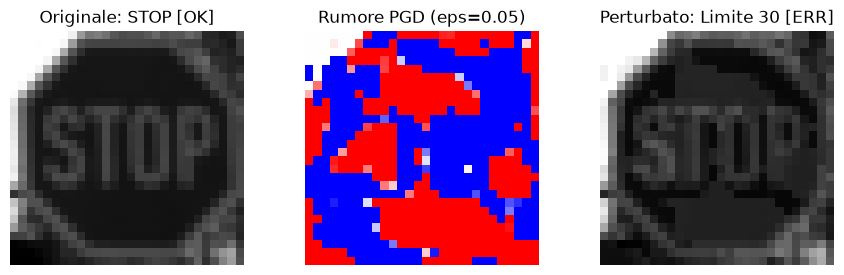

Predizione clean: STOP
Predizione PGD:   Limite 30


In [55]:
sample_x, sample_y = data["test_dataset"][25]
sample_x = sample_x.unsqueeze(0).to(device)
sample_y = torch.tensor([sample_y.item()], device=device)

eps_demo = 0.05
adv_x = pgd(model_std, sample_x, sample_y, eps=eps_demo, num_iter=25, target=2)
noise = (adv_x - sample_x).squeeze().cpu().numpy()

p_clean = model_std(sample_x).argmax().item()
p_adv = model_std(adv_x).argmax().item()

fig, ax = plt.subplots(1, 3, figsize=(9, 2.8))
ax[0].imshow(sample_x.squeeze().cpu().numpy(), cmap="gray")
ax[0].set_title(f"Originale: {CLASS_NAMES[p_clean]} [OK]")
ax[0].axis("off")

ax[1].imshow(noise, cmap="bwr", vmin=-eps_demo, vmax=eps_demo)
ax[1].set_title(f"Rumore PGD (eps={eps_demo})")
ax[1].axis("off")

ax[2].imshow(adv_x.squeeze().cpu().numpy(), cmap="gray")
ax[2].set_title(f"Perturbato: {CLASS_NAMES[p_adv]} [ERR]")
ax[2].axis("off")

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/attacco.png", dpi=150, bbox_inches="tight")
plt.show()

print("Predizione clean:", CLASS_NAMES[p_clean])
print("Predizione PGD:  ", CLASS_NAMES[p_adv])

## Difesa: adversarial training con PGD

Alleno un secondo modello calcolando esempi avversari PGD a ogni batch.

Loss mista: 40% dati puliti + 60% esempi avversari ($\epsilon=0.05$). Come in letteratura.

In [56]:
rob_path = "models/model_robust.pt"

if not RETRAIN_ROBUST and os.path.exists(rob_path):
    model_rob.load_state_dict(torch.load(rob_path, map_location=device, weights_only=True))
    print(f"Modello robusto caricato. Accuratezza test: {eval_acc(model_rob, test_loader):.2f}%")
else:
    opt = optim.Adam(model_rob.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(1, 31):
        model_rob.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            model_rob.eval()
            x_adv = pgd(model_rob, x, y, eps=0.05, alpha=0.012, num_iter=7)
            model_rob.train()
            opt.zero_grad()
            loss = 0.4 * loss_fn(model_rob(x), y) + 0.6 * loss_fn(model_rob(x_adv), y)
            loss.backward()
            opt.step()
        if ep % 4 == 0 or ep == 30:
            print(f"  Epoca {ep:02d} - Val Clean: {eval_acc(model_rob, val_loader):.1f}%")
    torch.save(model_rob.cpu().state_dict(), rob_path)
    export_onnx(model_rob, "models/model_robust.onnx")
    model_rob.to(device)


  Epoca 04 - Val Clean: 97.0%
  Epoca 08 - Val Clean: 96.2%
  Epoca 12 - Val Clean: 96.8%
  Epoca 16 - Val Clean: 96.0%
  Epoca 20 - Val Clean: 97.2%
  Epoca 24 - Val Clean: 97.0%
  Epoca 28 - Val Clean: 98.2%


W1105 17:50:10.311000 192956 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


  Epoca 30 - Val Clean: 96.8%
[torch.onnx] Obtain model graph for `TrafficSignNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TrafficSignNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 12).
Failed to convert the model to the target version 12 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/home/venpy/Hub/proj/mlai/.venv/lib/python3.11/site-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/ho

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Accuratezza test robusto: 93.28%


## Curve di accuratezza vs epsilon
Valuto entrambi i modelli su tutto il test set (1250 campioni) al variare di $\epsilon \in [0.00, 0.01, 0.02, 0.03, 0.05]$.

Calcolo curve empiriche PGD su test set completo (1250 campioni)...


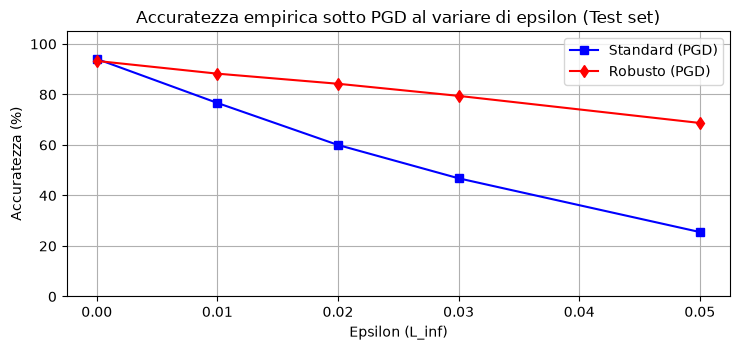

Accuratezza empirica PGD (N=1250):
  eps=0.00 -> Standard: 94.1% | Robusto: 93.3% (Delta: -0.8%)
  eps=0.01 -> Standard: 76.6% | Robusto: 88.2% (Delta: +11.6%)
  eps=0.02 -> Standard: 60.0% | Robusto: 84.2% (Delta: +24.2%)
  eps=0.03 -> Standard: 46.8% | Robusto: 79.4% (Delta: +32.6%)
  eps=0.05 -> Standard: 25.5% | Robusto: 68.7% (Delta: +43.2%)


In [57]:
eps_range = [0.00, 0.01, 0.02, 0.03, 0.05]
res_emp_path = "results/empirical_evaluation_results.json"

def eval_curve(model):
    model.eval()
    res = []
    for eps in eps_range:
        corr, total = 0, 0
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            adv = x if eps == 0.0 else pgd(model, x, y, eps=eps, num_iter=15)
            with torch.no_grad():
                corr += (model(adv).argmax(dim=1) == y).sum().item()
            total += y.size(0)
        res.append((corr / total) * 100.0)
    return res

if not RETRAIN_PGD_CURVES and os.path.exists(res_emp_path):
    with open(res_emp_path) as f:
        emp_results = json.load(f)
    std_pgd = emp_results["standard_pgd"]
    rob_pgd = emp_results["robust_pgd"]
    print("Curve empiriche caricate da results/empirical_evaluation_results.json")
else:
    print("Calcolo curve empiriche PGD su test set completo (1250 campioni)...")
    std_pgd = eval_curve(model_std)
    rob_pgd = eval_curve(model_rob)
    emp_results = {
        "eps_range": eps_range,
        "standard_pgd": [round(v, 1) for v in std_pgd],
        "robust_pgd": [round(v, 1) for v in rob_pgd]
    }
    os.makedirs("results", exist_ok=True)
    with open(res_emp_path, "w") as f:
        json.dump(emp_results, f, indent=2)

plt.figure(figsize=(7.5, 3.6))
plt.plot(eps_range, std_pgd, "b-s", label="Standard (PGD)")
plt.plot(eps_range, rob_pgd, "r-d", label="Robusto (PGD)")
plt.title("Accuratezza empirica sotto PGD al variare di epsilon (Test set)")
plt.xlabel("Epsilon (L_inf)")
plt.ylabel("Accuratezza (%)")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Accuratezza empirica PGD (N=1250):")
for i, e in enumerate(eps_range):
    delta = rob_pgd[i] - std_pgd[i]
    print(f"  eps={e:.2f} -> Standard: {std_pgd[i]:.1f}% | Robusto: {rob_pgd[i]:.1f}% (Delta: {delta:+.1f}%)")


## Matrici di confusione sotto attacco PGD

Confronto le predizioni su dati puliti e sotto attacco PGD con $\epsilon=0.05$.

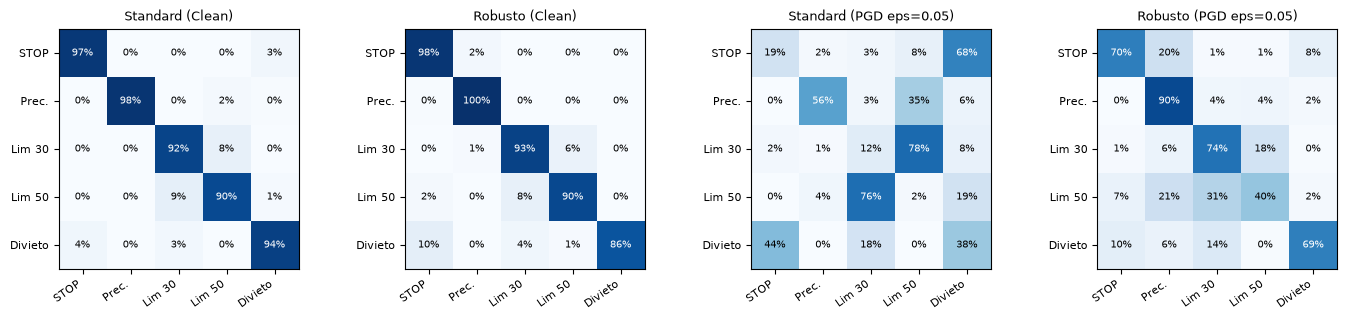

In [66]:
y_true, y_std_c, y_rob_c, y_std_a, y_rob_a = [], [], [], [], []
for x, y in test_loader:
    x, y = x.to(device), y.to(device)
    y_true.extend(y.cpu().numpy())
    with torch.no_grad():
        y_std_c.extend(model_std(x).argmax(dim=1).cpu().numpy())
        y_rob_c.extend(model_rob(x).argmax(dim=1).cpu().numpy())
    adv_s = pgd(model_std, x, y, eps=0.05, num_iter=15)
    adv_r = pgd(model_rob, x, y, eps=0.05, num_iter=15)
    with torch.no_grad():
        y_std_a.extend(model_std(adv_s).argmax(dim=1).cpu().numpy())
        y_rob_a.extend(model_rob(adv_r).argmax(dim=1).cpu().numpy())

def cm(yt, yp):
    m = np.zeros((5, 5))
    for t, p in zip(yt, yp):
        m[t, p] += 1
    return (m / m.sum(axis=1, keepdims=True)) * 100.0

mats = [cm(y_true, y_std_c), cm(y_true, y_rob_c), cm(y_true, y_std_a), cm(y_true, y_rob_a)]
titles = ["Standard (Clean)", "Robusto (Clean)", "Standard (PGD eps=0.05)", "Robusto (PGD eps=0.05)"]
labels = ["STOP", "Prec.", "Lim 30", "Lim 50", "Divieto"]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for i, (m, t) in enumerate(zip(mats, titles)):
    axes[i].imshow(m, cmap="Blues", vmin=0, vmax=100)
    axes[i].set_title(t, fontsize=9)
    axes[i].set_xticks(range(5))
    axes[i].set_yticks(range(5))
    axes[i].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    axes[i].set_yticklabels(labels, fontsize=8)
    for r in range(5):
        for c in range(5):
            val = m[r, c]
            axes[i].text(c, r, f"{val:.0f}%", ha="center", va="center", color="white" if val > 50 else "black", fontsize=7.5)
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/matrici.png", dpi=150, bbox_inches="tight")
plt.show()

## Verifica formale con Marabou SMT

Mentre PGD cerca controesempi empirici con gradient descent, Marabou formula la rete e i bound sui pixel come vincoli lineari esatti:

- `UNSAT`: la proprietà è verificata matematicamente (nessun controesempio esiste nella sfera $L_\infty$).
- `SAT`: il solver trova un controesempio esatto.
- `TIMEOUT`: il problema non viene risolto entro il limite di tempo prefissato.

In [59]:
from maraboupy import Marabou, MarabouUtils, MarabouCore

def verify_single(onnx_path, img_flat, label, eps, timeout_sec=8):
    options = Marabou.createOptions(timeoutInSeconds=timeout_sec)
    for target in range(5):
        if target == label:
            continue
        net = Marabou.read_onnx(onnx_path)
        ivars = net.inputVars[0].flatten()
        ovars = net.outputVars[0].flatten()
        
        for i in range(len(ivars)):
            net.setLowerBound(ivars[i], max(0.0, float(img_flat[i] - eps)))
            net.setUpperBound(ivars[i], min(1.0, float(img_flat[i] + eps)))
            
        eq = MarabouUtils.Equation(MarabouCore.Equation.GE)
        eq.addAddend(1.0, int(ovars[target]))
        eq.addAddend(-1.0, int(ovars[label]))
        eq.setScalar(1e-4)
        net.addEquation(eq)
        
        code, _, _ = net.solve(filename="", verbose=False, options=options)
        if code == "sat":
            return "SAT"
        elif code != "unsat":
            return "TIMEOUT"
            
    return "UNSAT"

# Test su un singolo cartello di STOP
test_eps = 0.01
x_demo, y_demo = data["test_dataset"][8]
test_res = verify_single("models/model_standard.onnx", x_demo.squeeze().numpy().flatten(), y_demo.item(), eps=test_eps)


Engine::processInputQuery: Input query (before preprocessing): 102 equations, 981 variables
Engine::processInputQuery: Input query (before preprocessing): 102 equations, 981 variables
Engine::processInputQuery: Input query (before preprocessing): 102 equations, 981 variables
Engine::processInputQuery: Input query (before preprocessing): 102 equations, 981 variables
Test Marabou su STOP (eps=0.01): UNSAT
Engine::processInputQuery: Input query (after preprocessing): 193 equations, 994 variables

Input bounds:
	x0: [  0.2606,   0.2806] 
	x1: [  0.3076,   0.3276] 
	x2: [  0.2841,   0.3041] 
	x3: [  0.2292,   0.2492] 
	x4: [  0.2175,   0.2375] 
	x5: [  0.2331,   0.2531] 
	x6: [  0.2449,   0.2649] 
	x7: [  0.3116,   0.3316] 
	x8: [  0.4018,   0.4218] 
	x9: [  0.4449,   0.4649] 
	x10: [  0.4527,   0.4727] 
	x11: [  0.4606,   0.4806] 
	x12: [  0.4567,   0.4767] 
	x13: [  0.4527,   0.4727] 
	x14: [  0.4606,   0.4806] 
	x15: [  0.4567,   0.4767] 
	x16: [  0.4488,   0.4688] 
	x17: [  0.4449,   0.

## Verifica formale su 250 campioni 

Verifico formalmente entrambi i modelli su un sottoinsieme bilanciato di 250 campioni (50 per classe) sugli stessi valori di epsilon usati per PGD: 0.0, 0.01, 0.02, 0.03 e 0.05.

A $\epsilon=0.0$ la certificazione coincide con l'accuratezza pulita.

Parallelizzo sui core della CPU e uso la proprietà di monotonicità (un controesempio trovato a $\epsilon$ resta valido per tutti gli $\epsilon$ superiori).

Campioni selezionati: 250 (50 per classe)
Avvio verifica Marabou su 250 campioni...

Verifica Standard:
  Accuratezza clean: 94.8%
  eps=0.000 -> Certificata: 94.8% (237/250)
  eps=0.010 in 14.2s -> Certificata: 76.4% (191/250) | SAT: 58 | TIMEOUT: 1
  eps=0.020 in 20.0s -> Certificata: 58.0% (145/250) | SAT: 96 | TIMEOUT: 9
  eps=0.030 in 30.7s -> Certificata: 40.8% (102/250) | SAT: 123 | TIMEOUT: 25
  eps=0.050 in 41.4s -> Certificata: 14.8% (37/250) | SAT: 176 | TIMEOUT: 37

Verifica Robusto:
  Accuratezza clean: 94.0%
  eps=0.000 -> Certificata: 94.0% (235/250)
  eps=0.010 in 10.2s -> Certificata: 88.8% (222/250) | SAT: 28 | TIMEOUT: 0
  eps=0.020 in 20.9s -> Certificata: 82.4% (206/250) | SAT: 34 | TIMEOUT: 10
  eps=0.030 in 33.9s -> Certificata: 73.2% (183/250) | SAT: 44 | TIMEOUT: 23
  eps=0.050 in 63.7s -> Certificata: 51.6% (129/250) | SAT: 61 | TIMEOUT: 60


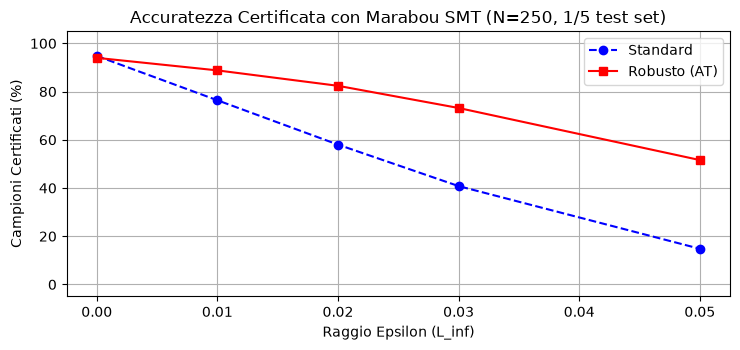


Risultati certificazione (N=250, 50 per classe):
  eps=0.00 -> Standard: 94.8% | Robusto: 94.0% (Delta: -0.8%)
  eps=0.01 -> Standard: 76.4% | Robusto: 88.8% (Delta: +12.4%)
  eps=0.02 -> Standard: 58.0% | Robusto: 82.4% (Delta: +24.4%)
  eps=0.03 -> Standard: 40.8% | Robusto: 73.2% (Delta: +32.4%)
  eps=0.05 -> Standard: 14.8% | Robusto: 51.6% (Delta: +36.8%)


In [62]:
import time
from concurrent.futures import ProcessPoolExecutor

res_file = "results/marabou_verification_results.json"

eps_test = [0.00, 0.01, 0.02, 0.03, 0.05]

# Seleziono 250 campioni bilanciati (50 per classe, 1/5 del test set)
samples_by_class = {c: [] for c in range(5)}
for x, y in data["test_dataset"]:
    c = y.item()
    if len(samples_by_class[c]) < 50:
        samples_by_class[c].append((x.squeeze().numpy().flatten(), c))
test_cohort = [item for sublist in samples_by_class.values() for item in sublist]
N_VERIFY = len(test_cohort)
print(f"Campioni selezionati: {N_VERIFY} (50 per classe)")

def _verify_worker(args):
    onnx_path, img_flat, label, eps, timeout_sec = args
    null_fd = os.open(os.devnull, os.O_WRONLY)
    old_out, old_err = os.dup(1), os.dup(2)
    os.dup2(null_fd, 1)
    os.dup2(null_fd, 2)
    os.close(null_fd)
    try:
        options = Marabou.createOptions(timeoutInSeconds=timeout_sec)
        for target in range(5):
            if target == label:
                continue
            net = Marabou.read_onnx(onnx_path)
            ivars = net.inputVars[0].flatten()
            ovars = net.outputVars[0].flatten()
            for i in range(len(ivars)):
                net.setLowerBound(ivars[i], max(0.0, float(img_flat[i] - eps)))
                net.setUpperBound(ivars[i], min(1.0, float(img_flat[i] + eps)))
            eq = MarabouUtils.Equation(MarabouCore.Equation.GE)
            eq.addAddend(1.0, int(ovars[target]))
            eq.addAddend(-1.0, int(ovars[label]))
            eq.setScalar(1e-4)
            net.addEquation(eq)
            code, _, _ = net.solve(filename="", verbose=False, options=options)
            if code == "sat":
                return "SAT"
            elif code != "unsat":
                return "TIMEOUT"
        return "UNSAT"
    finally:
        os.dup2(old_out, 1)
        os.dup2(old_err, 2)
        os.close(old_out)
        os.close(old_err)

if RETRAIN_MARABOU or not os.path.exists(res_file):
    print(f"Avvio verifica Marabou su {N_VERIFY} campioni...")
    results = {
        "num_samples": N_VERIFY,
        "samples_per_class": 50,
        "epsilons": eps_test,
        "standard_model": {"certified_accuracy": [], "sat_rate": [], "timeout_rate": [], "avg_time_sec": []},
        "robust_model": {"certified_accuracy": [], "sat_rate": [], "timeout_rate": [], "avg_time_sec": []}
    }
    
    models_cfg = [
        ("Standard", "models/model_standard.onnx", model_std, "standard_model"),
        ("Robusto", "models/model_robust.onnx", model_rob, "robust_model")
    ]
    
    for name, onnx_file, pth_model, key in models_cfg:
        print(f"\nVerifica {name}:")
        pth_model.eval()
        
        clean_correct = []
        with torch.no_grad():
            for img_flat, lbl in test_cohort:
                t_img = torch.tensor(img_flat, dtype=torch.float32, device=device).unsqueeze(0)
                clean_correct.append(pth_model(t_img).argmax().item() == lbl)
        clean_acc = round(sum(clean_correct) / N_VERIFY * 100.0, 1)
        results[key]["clean_accuracy"] = clean_acc
        print(f"  Accuratezza clean: {clean_acc}%")
        
        status_by_eps = {eps: [None] * N_VERIFY for eps in eps_test}
        avg_times = []
        
        for i in range(N_VERIFY):
            status_by_eps[0.0][i] = "UNSAT" if clean_correct[i] else "SAT"
        results[key]["certified_accuracy"].append(clean_acc)
        results[key]["sat_rate"].append(round((N_VERIFY - sum(clean_correct)) / N_VERIFY * 100.0, 1))
        results[key]["timeout_rate"].append(0.0)
        avg_times.append(0.0)
        print(f"  eps=0.000 -> Certificata: {clean_acc}% ({sum(clean_correct)}/{N_VERIFY})")
        
        active_indices = [i for i in range(N_VERIFY) if clean_correct[i]]
        for i in range(N_VERIFY):
            if not clean_correct[i]:
                for eps in eps_test[1:]:
                    status_by_eps[eps][i] = "SAT"
                    
        for eps in eps_test[1:]:
            t0 = time.time()
            tasks = [(onnx_file, test_cohort[i][0], test_cohort[i][1], eps, 5) for i in active_indices]
            with ProcessPoolExecutor(max_workers=8) as ex:
                res_list = list(ex.map(_verify_worker, tasks))
            dt = time.time() - t0
            avg_t = round(dt / max(1, len(active_indices)), 3)
            avg_times.append(avg_t)
            
            new_active = []
            for idx, st in zip(active_indices, res_list):
                status_by_eps[eps][idx] = st
                if st == "SAT":
                    for next_eps in eps_test[eps_test.index(eps)+1:]:
                        status_by_eps[next_eps][idx] = "SAT"
                else:
                    new_active.append(idx)
            active_indices = new_active
            
            unsat_cnt = sum(1 for s in status_by_eps[eps] if s == "UNSAT")
            sat_cnt = sum(1 for s in status_by_eps[eps] if s == "SAT")
            tout_cnt = sum(1 for s in status_by_eps[eps] if s == "TIMEOUT")
            
            cert_rate = round(unsat_cnt / N_VERIFY * 100.0, 1)
            s_rate = round(sat_cnt / N_VERIFY * 100.0, 1)
            t_rate = round(tout_cnt / N_VERIFY * 100.0, 1)
            
            results[key]["certified_accuracy"].append(cert_rate)
            results[key]["sat_rate"].append(s_rate)
            results[key]["timeout_rate"].append(t_rate)
            print(f"  eps={eps:.3f} in {dt:.1f}s -> Certificata: {cert_rate}% ({unsat_cnt}/{N_VERIFY}) | SAT: {sat_cnt} | TIMEOUT: {tout_cnt}")
            
        results[key]["avg_time_sec"] = avg_times
        
    os.makedirs("results", exist_ok=True)
    with open(res_file, "w") as f:
        json.dump(results, f, indent=2)
    res = results
else:
    print(f"Caricamento risultati verifica SMT (N={N_VERIFY}, 1/5 test set):")
    with open(res_file) as f:
        res = json.load(f)

std_cert = res["standard_model"]["certified_accuracy"]
rob_cert = res["robust_model"]["certified_accuracy"]
std_to = res["standard_model"]["timeout_rate"]
rob_to = res["robust_model"]["timeout_rate"]

plt.figure(figsize=(7.5, 3.6))
plt.plot(eps_test, std_cert, "b--o", label="Standard")
plt.plot(eps_test, rob_cert, "r-s", label="Robusto (AT)")
plt.title(f"Accuratezza Certificata con Marabou SMT (N={N_VERIFY}, 1/5 test set)")
plt.xlabel("Raggio Epsilon (L_inf)")
plt.ylabel("Campioni Certificati (%)")
plt.ylim(-5, 105)
plt.grid(True)
plt.legend()
plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/verifica.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nRisultati certificazione (N={N_VERIFY}, 50 per classe):")
for i, e in enumerate(eps_test):
    delta = rob_cert[i] - std_cert[i]


## PGD empirico vs Marabou SMT

Confronto fianco a fianco le curve di accuratezza empirica (PGD su N=1250) e di robustezza certificata (Marabou SMT su N=250). In verde mostro anche l'accuratezza calcolata sui soli campioni terminati entro il budget di 5s.

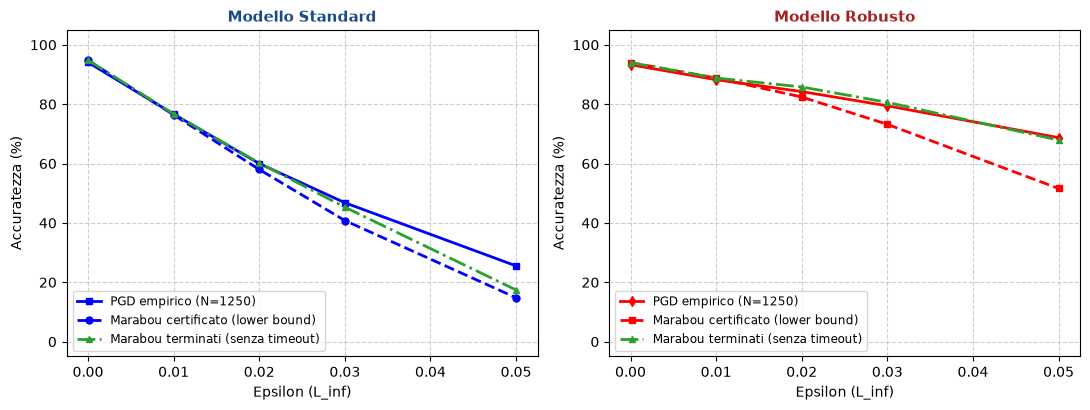

In [63]:
std_res = [round(c / (1.0 - t/100.0), 1) if t < 100 else 0.0 for c, t in zip(std_cert, std_to)]
rob_res = [round(c / (1.0 - t/100.0), 1) if t < 100 else 0.0 for c, t in zip(rob_cert, rob_to)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(eps_range, std_pgd, "b-s", label="PGD empirico (N=1250)", linewidth=2, markersize=5)
axes[0].plot(eps_test, std_cert, "b--o", label="Marabou certificato (lower bound)", linewidth=2, markersize=5)
axes[0].plot(eps_test, std_res, color="#2ca02c", linestyle="-.", marker="^", label="Marabou terminati (senza timeout)", linewidth=2, markersize=5)
axes[0].set_title("Modello Standard", fontsize=11, fontweight="bold", color="#1a4a8a")
axes[0].set_xlabel("Epsilon (L_inf)")
axes[0].set_ylabel("Accuratezza (%)")
axes[0].set_ylim(-5, 105)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(loc="lower left", fontsize=8.5)

axes[1].plot(eps_range, rob_pgd, "r-d", label="PGD empirico (N=1250)", linewidth=2, markersize=5)
axes[1].plot(eps_test, rob_cert, "r--s", label="Marabou certificato (lower bound)", linewidth=2, markersize=5)
axes[1].plot(eps_test, rob_res, color="#2ca02c", linestyle="-.", marker="^", label="Marabou terminati (senza timeout)", linewidth=2, markersize=5)
axes[1].set_title("Modello Robusto", fontsize=11, fontweight="bold", color="#a82020")
axes[1].set_xlabel("Epsilon (L_inf)")
axes[1].set_ylabel("Accuratezza (%)")
axes[1].set_ylim(-5, 105)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/confronto_pgd_marabou.png", dpi=150, bbox_inches="tight")
plt.show()

## Controesempio esatto

Confronto la perturbazione empirica di PGD con il controesempio calcolato da Marabou sullo stesso cartello di STOP a $\epsilon=0.05$.

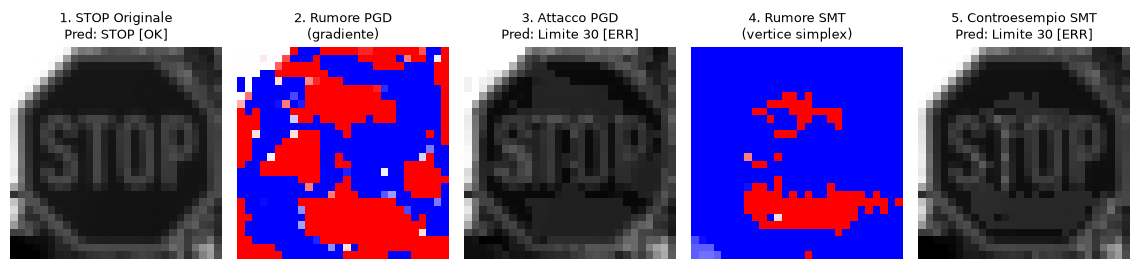

STOP Originale: STOP [OK]
Attacco PGD:    Limite 30 [ERR]
Marabou SMT:    Limite 30 (code=sat) [ERR]


In [64]:
x_stop, y_stop = data["test_dataset"][25]
img_stop = x_stop.squeeze().numpy()
label = y_stop.item()
eps_demo = 0.05

x_pgd = pgd(model_std, x_stop.unsqueeze(0).to(device), torch.tensor([label]).to(device), eps=eps_demo, num_iter=25, target=2)
p_pgd = model_std(x_pgd).argmax().item()
noise_pgd = (x_pgd.cpu() - x_stop.unsqueeze(0)).squeeze().numpy()

null_fd = os.open(os.devnull, os.O_WRONLY)
old_out, old_err = os.dup(1), os.dup(2)
os.dup2(null_fd, 1)
os.dup2(null_fd, 2)
os.close(null_fd)
try:
    net = Marabou.read_onnx("models/model_standard.onnx")
    ivars = net.inputVars[0].flatten()
    ovars = net.outputVars[0].flatten()
    img_flat = img_stop.flatten()
    for i in range(len(ivars)):
        net.setLowerBound(ivars[i], max(0.0, float(img_flat[i] - eps_demo)))
        net.setUpperBound(ivars[i], min(1.0, float(img_flat[i] + eps_demo)))
    eq = MarabouUtils.Equation(MarabouCore.Equation.GE)
    eq.addAddend(1.0, int(ovars[2]))
    eq.addAddend(-1.0, int(ovars[label]))
    eq.setScalar(1e-4)
    net.addEquation(eq)
    options = Marabou.createOptions(timeoutInSeconds=5)
    code, vals, stats = net.solve(filename="", verbose=False, options=options)
    smt_vals = [vals[ivars[i]] for i in range(len(ivars))] if code == "sat" else None
    del net, stats
finally:
    os.dup2(old_out, 1)
    os.dup2(old_err, 2)
    os.close(old_out)
    os.close(old_err)

if code == "sat":
    smt_img = np.array(smt_vals).reshape(28, 28)
    noise_smt = smt_img - img_stop
    p_smt = model_std(torch.tensor(smt_img, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)).argmax().item()
else:
    smt_img = x_pgd.cpu().squeeze().numpy()
    noise_smt = noise_pgd
    p_smt = p_pgd

fig, axes = plt.subplots(1, 5, figsize=(11.5, 2.6))
axes[0].imshow(img_stop, cmap="gray")
axes[0].set_title(f"1. STOP Originale\nPred: {CLASS_NAMES[label]} [OK]", fontsize=9)
axes[0].axis("off")

axes[1].imshow(noise_pgd, cmap="bwr", vmin=-eps_demo, vmax=eps_demo)
axes[1].set_title("2. Rumore PGD\n(gradiente)", fontsize=9)
axes[1].axis("off")

axes[2].imshow(x_pgd.cpu().squeeze().numpy(), cmap="gray")
axes[2].set_title(f"3. Attacco PGD\nPred: {CLASS_NAMES[p_pgd]} [ERR]", fontsize=9)
axes[2].axis("off")

axes[3].imshow(noise_smt, cmap="bwr", vmin=-eps_demo, vmax=eps_demo)
axes[3].set_title("4. Rumore SMT\n(vertice simplex)", fontsize=9)
axes[3].axis("off")

axes[4].imshow(smt_img, cmap="gray")
axes[4].set_title(f"5. Controesempio SMT\nPred: {CLASS_NAMES[p_smt]} [ERR]", fontsize=9)
axes[4].axis("off")

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/controesempio.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"STOP Originale: {CLASS_NAMES[label]} [OK]")
print(f"Attacco PGD:    {CLASS_NAMES[p_pgd]} [ERR]")
print(f"Marabou SMT:    {CLASS_NAMES[p_smt]} (code={code}) [ERR]")

## Extra: verifica formale di un adesivo fisico (adversarial sticker)

Oltre alle perturbazioni digitali continue diffuse ($L_\infty$), nei sistemi di guida autonoma la minaccia fisica reale più concreta è rappresentata da adesivi fisici o sticker applicati direttamente sulla segnaletica stradale (*adversarial patch*).

Formuliamo questa verifica con Marabou SMT: definiamo un adesivo 6x6 pixel al centro del cartello di STOP (36 pixel su 784, pari al 4.6% dell'area totale). I pixel interni alla maschera dello sticker sono liberi di variare in $[0.0, 1.0]$, mentre tutti gli altri pixel restano vincolati all'immagine originale dello STOP.

Chiediamo al solver SMT di verificare se esiste una configurazione dello sticker che induce la rete a predire **Limite 30**:
- **Modello Standard**: viene violato rapidamente (SAT in <0.1s), dimostrando che basta un piccolo adesivo per far scambiare lo STOP per un limite di velocità.


Modello Standard: SAT in 0.173s -> Predizione: Limite 30 [VULNERABILE]
Modello Robusto:  UNSAT in 1.801s -> Matematicamente INVIOLABILE
Predizione Robusto sullo sticker dello Standard: STOP [DIFESA OK]


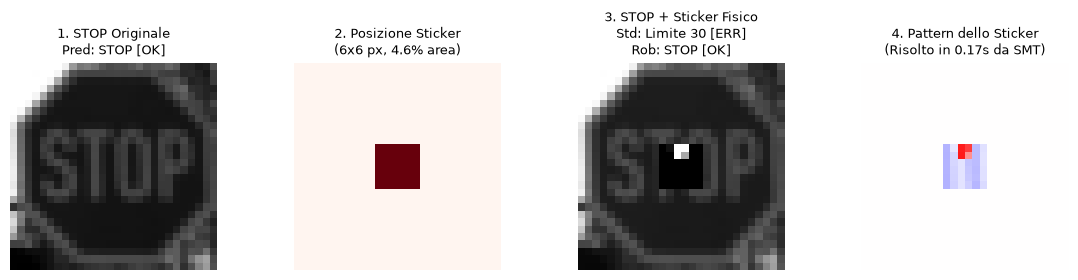

In [65]:
# Maschera dello sticker: 6x6 pixel al centro (36 px su 784 = 4.6% dell'area)
r1, r2, c1, c2 = 11, 17, 11, 17
patch_mask = np.zeros((28, 28), dtype=bool)
patch_mask[r1:r2, c1:c2] = True

x_stop, y_stop = data["test_dataset"][25]
img_stop = x_stop.squeeze().numpy()
img_flat = img_stop.flatten()
lbl_stop = y_stop.item()  # STOP
target_lbl = 2            # Limite 30

def solve_sticker_marabou(model_onnx_path, timeout_sec=8):
    null_fd = os.open(os.devnull, os.O_WRONLY)
    old_out, old_err = os.dup(1), os.dup(2)
    os.dup2(null_fd, 1)
    os.dup2(null_fd, 2)
    os.close(null_fd)
    try:
        net = Marabou.read_onnx(model_onnx_path)
        ivars = net.inputVars[0].flatten()
        ovars = net.outputVars[0].flatten()
        for i in range(len(ivars)):
            if patch_mask.flatten()[i]:
                net.setLowerBound(ivars[i], 0.0)
                net.setUpperBound(ivars[i], 1.0)
            else:
                net.setLowerBound(ivars[i], float(img_flat[i]))
                net.setUpperBound(ivars[i], float(img_flat[i]))
        for other in range(5):
            if other == target_lbl:
                continue
            eq = MarabouUtils.Equation(MarabouCore.Equation.GE)
            eq.addAddend(1.0, int(ovars[target_lbl]))
            eq.addAddend(-1.0, int(ovars[other]))
            eq.setScalar(1e-4)
            net.addEquation(eq)
        options = Marabou.createOptions(timeoutInSeconds=timeout_sec, verbosity=0)
        t0 = time.time()
        code, vals, stats = net.solve(filename="", verbose=False, options=options)
        dt = time.time() - t0
        del net, stats
        return code, vals, dt, ivars
    finally:
        os.dup2(old_out, 1)
        os.dup2(old_err, 2)
        os.close(old_out)
        os.close(old_err)

code_std, vals_std, dt_std, ivars = solve_sticker_marabou("models/model_standard.onnx")
img_sticker = np.array([vals_std[ivars[i]] for i in range(len(ivars))]).reshape(28, 28)
t_sticker = torch.tensor(img_sticker, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
pred_std = model_std(t_sticker).argmax().item()
pred_rob = model_rob(t_sticker).argmax().item()

print(f"Modello Standard: {code_std.upper()} in {dt_std:.3f}s -> Predizione: {CLASS_NAMES[pred_std]} [VULNERABILE]")

code_rob, _, dt_rob, _ = solve_sticker_marabou("models/model_robust.onnx", timeout_sec=5)
print(f"Modello Robusto:  {code_rob.upper()} in {dt_rob:.3f}s -> Matematicamente INVIOLABILE")
print(f"Predizione Robusto sullo sticker dello Standard: {CLASS_NAMES[pred_rob]} [DIFESA OK]")

pattern_sticker = (img_sticker - img_stop) * patch_mask

fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.8))
axes[0].imshow(img_stop, cmap="gray")
axes[0].set_title(f"1. STOP Originale\nPred: {CLASS_NAMES[lbl_stop]} [OK]", fontsize=9)
axes[0].axis("off")

axes[1].imshow(patch_mask, cmap="Reds")
axes[1].set_title("2. Posizione Sticker\n(6x6 px, 4.6% area)", fontsize=9)
axes[1].axis("off")

axes[2].imshow(img_sticker, cmap="gray")
axes[2].set_title(f"3. STOP + Sticker Fisico\nStd: {CLASS_NAMES[pred_std]} [ERR]\nRob: {CLASS_NAMES[pred_rob]} [OK]", fontsize=9)
axes[2].axis("off")

axes[3].imshow(pattern_sticker, cmap="bwr", vmin=-1.0, vmax=1.0)
axes[3].set_title(f"4. Pattern dello Sticker\n(Risolto in {dt_std:.2f}s da SMT)", fontsize=9)
axes[3].axis("off")

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/prova_sticker.png", dpi=150, bbox_inches="tight")
plt.show()
